# Explainable AI (SHAP), Feature Selection & Threshold Optimization (Merged 4-Class)

This notebook computes **Global & Local SHAP explanations** across 10 representative models, performs consensus **SHAP-guided Feature Selection** (`k = 27`), and optimizes the two-threshold risk zoning (`TAU_LOW = 0.58`, `TAU_HIGH = 0.72`):
1. **Set up & Load Val Set / Hard Cases / Models:** Load `Models/Train_Test/merged/val.csv` (`121,095` rows), `Models/hard_cases_merged.csv`, and 10 trained models grouped into `TreeExplainer` (5), `LinearExplainer` (3), and `KernelExplainer` (2).
2. **Calculate SHAP Global Importance (Tier 1):** Compute global `mean(|SHAP|)` rankings across 8 fast models (Tree + Linear) and save `Reports/shap_values_global.pkl`.
3. **Charts + Consensus Feature Ranking:** Build the cross-model consensus table (`mean_rank`, `mean_norm_shap`, `n_models_top10`) and summary plots (`Reports/Images/shap/`).
4. **Local Explanation on Hard Cases (Tier 2):** Run Tree/Linear SHAP on all hard cases and stratified Kernel SHAP (`2,500` samples) for `bagging` + `knn` (`Reports/shap_values_hard_cases.pkl`, `Reports/shap_values_kernel_hard_cases.pkl`).
5. **Misclassification Diagnosis & Waterfall Plots:** Compare Tier-2 (misclassified) vs. Tier-1 (global) SHAP importance and generate local waterfall plots for the worst misclassified phishing URL.
6. **SHAP-Guided Feature Selection (`k = 27`):** Evaluate top-$k$ feature subsets across 3 top models with bootstrap 95% CIs, retain domain-knowledge features (`is_suspicious_tld`, `has_suspicious_word`), and export `Models/final_features.json`.
7. **Final Evaluation & Two-Threshold Optimization:** Split Validation into Split A (threshold tuning) and Split B (`60,548` samples for unbiased reporting), selecting `TAU_HIGH = 0.72` (`~1%` FPR) and `TAU_LOW = 0.58` (`~4%` FPR) and exporting `Api/deploy_bundle.pkl`.

## 1. Set up

In [1]:
import os
import numpy as np
import pandas as pd
import joblib
import time
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import seaborn as sns

import shap

# ── Đường dẫn — dùng chung logic với modeling.ipynb (BASE_DIR tính động theo cwd) ──
BASE_DIR       = os.path.abspath(os.path.join(os.getcwd(), '..'))
MODELS_DIR     = os.path.join(BASE_DIR, 'Models')
TRAIN_TEST_DIR = os.path.join(MODELS_DIR, 'Train_Test')
REPORTS_DIR    = os.path.join(BASE_DIR, 'Reports')
IMAGES_DIR     = os.path.join(REPORTS_DIR, 'Images', 'shap')
API_DIR        = os.path.join(BASE_DIR, 'Api')
os.makedirs(IMAGES_DIR, exist_ok=True)

print(f"BASE_DIR   : {BASE_DIR}")
print(f"MODELS_DIR : {MODELS_DIR}")
print(f"IMAGES_DIR : {IMAGES_DIR}")
print(f"API_DIR    : {API_DIR}")

BASE_DIR   : d:\Study Assets\Final Project\PhishingGuard
MODELS_DIR : d:\Study Assets\Final Project\PhishingGuard\Models
IMAGES_DIR : d:\Study Assets\Final Project\PhishingGuard\Reports\Images\shap
API_DIR    : d:\Study Assets\Final Project\PhishingGuard\Api


## 2. Load Val Set + Hard Cases + Scaler

In [2]:
# ── Val set Merged (dùng để tính Global Feature Importance) ──
val = pd.read_csv(os.path.join(TRAIN_TEST_DIR, 'merged', 'val.csv'))
FEATURE_COLS = [c for c in val.columns if c not in ['URL', 'Label']]

# Label mapping — LabelEncoder gốc sort alphabet, tái tạo lại chính xác mapping đó
LABEL_NAMES = sorted(val['Label'].unique())
label_to_idx = {name: i for i, name in enumerate(LABEL_NAMES)}
print(f"Label mapping: {label_to_idx}")

X_val = val[FEATURE_COLS].values
y_val = val['Label'].map(label_to_idx).values

# ── Scaler đã lưu — bắt buộc dùng lại đúng scaler đã fit lúc train, không fit mới ──
scaler = joblib.load(os.path.join(MODELS_DIR, 'merged', 'scaler.pkl'))
X_val_scaled = scaler.transform(X_val)

print(f"\nVal set Merged: {X_val.shape}")
print(f"Feature columns ({len(FEATURE_COLS)}): {FEATURE_COLS}")

# ── Hard cases từ Error Analysis (modeling.ipynb, mục 13.5) ──
hard_cases = pd.read_csv(os.path.join(MODELS_DIR, 'hard_cases_merged.csv'))
X_hard = hard_cases[FEATURE_COLS].values
y_hard = hard_cases['Label'].map(label_to_idx).values
X_hard_scaled = scaler.transform(X_hard)

print(f"\nHard cases: {X_hard.shape[0]} samples")
print(hard_cases['Label'].value_counts())

Label mapping: {'benign': 0, 'defacement': 1, 'malware': 2, 'phishing': 3}

Val set Merged: (121095, 32)
Feature columns (32): ['url_length', 'domain_length', 'path_length', 'num_dots', 'domain_hyphens', 'path_hyphens', 'num_underscores', 'num_slashes', 'num_at', 'num_question_marks', 'num_equals', 'num_ampersands', 'num_percent', 'num_digits', 'digit_ratio', 'letter_ratio', 'url_entropy', 'domain_entropy', 'num_subdomains', 'has_ip_address', 'is_suspicious_tld', 'has_port', 'path_depth', 'num_query_params', 'has_fragment', 'is_shortened_url', 'has_suspicious_word', 'consonant_ratio', 'vowel_ratio', 'longest_token_length', 'avg_token_length', 'special_char_ratio']

Hard cases: 10836 samples
Label
phishing      5429
defacement    2753
benign        2040
malware        614
Name: count, dtype: int64


### 2.1 Load 10 Representative Models (Merged) & Group by SHAP Explainer Type

In [3]:
# ── Phân nhóm model theo loại explainer phù hợp (đã chốt) ──
TREE_MODELS = [
    'decision_tree', 'random_forest', 'xgboost',
    'lightgbm', 'extra_trees'
]  # shap.TreeExplainer — đã bỏ gradient_boosting (shap issue #2887, #479 — không hỗ trợ multiclass)

LINEAR_MODELS = [
    'logistic_regression_custom_manual', 'svm', 'sgd'
]  # shap.LinearExplainer — đã bỏ logistic_regression (balanced), giữ bản custom_manual

KERNEL_MODELS = [
    'bagging', 'knn'
]  # shap.KernelExplainer — chỉ giữ 2 model tốt nhất nhóm này

# Model cần input đã scale (StandardScaler)
SCALED_MODELS = {
    'knn', 'svm', 'sgd', 'logistic_regression_custom_manual'
}

ALL_MODEL_KEYS = TREE_MODELS + LINEAR_MODELS + KERNEL_MODELS
print(f"Total models selected for Explainability: {len(ALL_MODEL_KEYS)}/16")

models = {}
for key in ALL_MODEL_KEYS:
    path = os.path.join(MODELS_DIR, 'merged', f'{key}.pkl')
    if not os.path.exists(path):
        print(f"  [MISSING] {path}")
        continue
    models[key] = joblib.load(path)

print(f"Loaded {len(models)}/{len(ALL_MODEL_KEYS)} models (Merged)")
print(f"\n  Tree-based   ({len(TREE_MODELS)}) : {TREE_MODELS}")
print(f"  Linear       ({len(LINEAR_MODELS)}) : {LINEAR_MODELS}")
print(f"  Kernel-based ({len(KERNEL_MODELS)}) : {KERNEL_MODELS}")

def get_input(model_key, X_raw, X_scaled):
    """Trả về đúng loại input (scaled/raw) theo model_key."""
    return X_scaled if model_key in SCALED_MODELS else X_raw

Total models selected for Explainability: 10/16
Loaded 10/10 models (Merged)

  Tree-based   (5) : ['decision_tree', 'random_forest', 'xgboost', 'lightgbm', 'extra_trees']
  Linear       (3) : ['logistic_regression_custom_manual', 'svm', 'sgd']
  Kernel-based (2) : ['bagging', 'knn']


## 3. Calculate SHAP Global Importance (Tier 1)

In [4]:
# ── 3. Global Feature Importance (SHAP) — Tree + Linear models (8 model) ──

N_BACKGROUND     = 200   # nền cho LinearExplainer
N_GLOBAL_SAMPLE  = 3000  # số sample val dùng để tính global importance
FORCE_RECOMPUTE_GLOBAL = False  # đổi thành True nếu muốn tính lại toàn bộ từ đầu

GLOBAL_CHECKPOINT_PATH = os.path.join(BASE_DIR, 'Reports', 'shap_values_global.pkl')

rng = np.random.RandomState(42)
sample_idx = rng.choice(len(X_val), size=N_GLOBAL_SAMPLE, replace=False)

# Tự động nạp checkpoint nếu đã có (tránh mất công tính lại khi bị ngắt)
if not FORCE_RECOMPUTE_GLOBAL and os.path.exists(GLOBAL_CHECKPOINT_PATH):
    shap_values_global = joblib.load(GLOBAL_CHECKPOINT_PATH)
    print(f"Loaded Global SHAP checkpoint ({len(shap_values_global)} models): {GLOBAL_CHECKPOINT_PATH}")
else:
    shap_values_global = {}  # model_key -> {'values': list mảng SHAP theo từng class, 'X_sample': ...}

for model_key in TREE_MODELS + LINEAR_MODELS:
    model = models[model_key]
    X_full = get_input(model_key, X_val, X_val_scaled)
    X_sample = X_full[sample_idx]

    # Bỏ qua model đã có trong checkpoint và khớp kích thước dữ liệu hiện tại
    if model_key in shap_values_global:
        cached_sv = shap_values_global[model_key]['values']
        if len(cached_sv) > 0 and cached_sv[0].shape[:2] == X_sample.shape:
            print(f"[SKIP  ] {model_key:35s} → loaded from checkpoint, shape {cached_sv[0].shape}")
            continue

    t0 = time.time()
    try:
        if model_key in TREE_MODELS:
            explainer = shap.TreeExplainer(model)
            sv = explainer.shap_values(X_sample)
        else:  # LINEAR_MODELS
            bg_idx = rng.choice(len(X_full), N_BACKGROUND, replace=False)
            background = X_full[bg_idx]
            explainer = shap.LinearExplainer(model, background)
            sv = explainer.shap_values(X_sample)

        # Chuẩn hóa về dạng list-of-arrays theo từng class (multiclass 4 lớp)
        if isinstance(sv, list):
            sv_list = sv
        elif sv.ndim == 3:
            sv_list = [sv[:, :, c] for c in range(sv.shape[2])]
        else:
            sv_list = [sv]

        elapsed = round(time.time() - t0, 1)
        shap_values_global[model_key] = {'values': sv_list, 'X_sample': X_sample}
        print(f"[{elapsed:>6}s] {model_key:35s} → {len(sv_list)} class(es), shape {sv_list[0].shape}")

        # Checkpoint — lưu ngay sau mỗi model
        joblib.dump(shap_values_global, GLOBAL_CHECKPOINT_PATH)

    except Exception as e:
        print(f"[FAILED] {model_key}: {e}")

print(f"\nCompleted Global SHAP for {len(shap_values_global)}/{len(TREE_MODELS)+len(LINEAR_MODELS)} models")

[   3.5s] decision_tree                       → 4 class(es), shape (3000, 32)
[3004.3s] random_forest                       → 4 class(es), shape (3000, 32)
[   1.5s] xgboost                             → 4 class(es), shape (3000, 32)
[   1.2s] lightgbm                            → 4 class(es), shape (3000, 32)


Background dataset has 200 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=200 when initializing the masker.
Background dataset has 200 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=200 when initializing the masker.
Background dataset has 200 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=200 when initializing the masker.


[1344.3s] extra_trees                         → 4 class(es), shape (3000, 32)
[   0.0s] logistic_regression_custom_manual   → 4 class(es), shape (3000, 32)
[   0.0s] svm                                 → 4 class(es), shape (3000, 32)
[   0.0s] sgd                                 → 4 class(es), shape (3000, 32)

Completed Global SHAP for 8/8 models


## 4. Charts + Top Comparison Features Table between Models

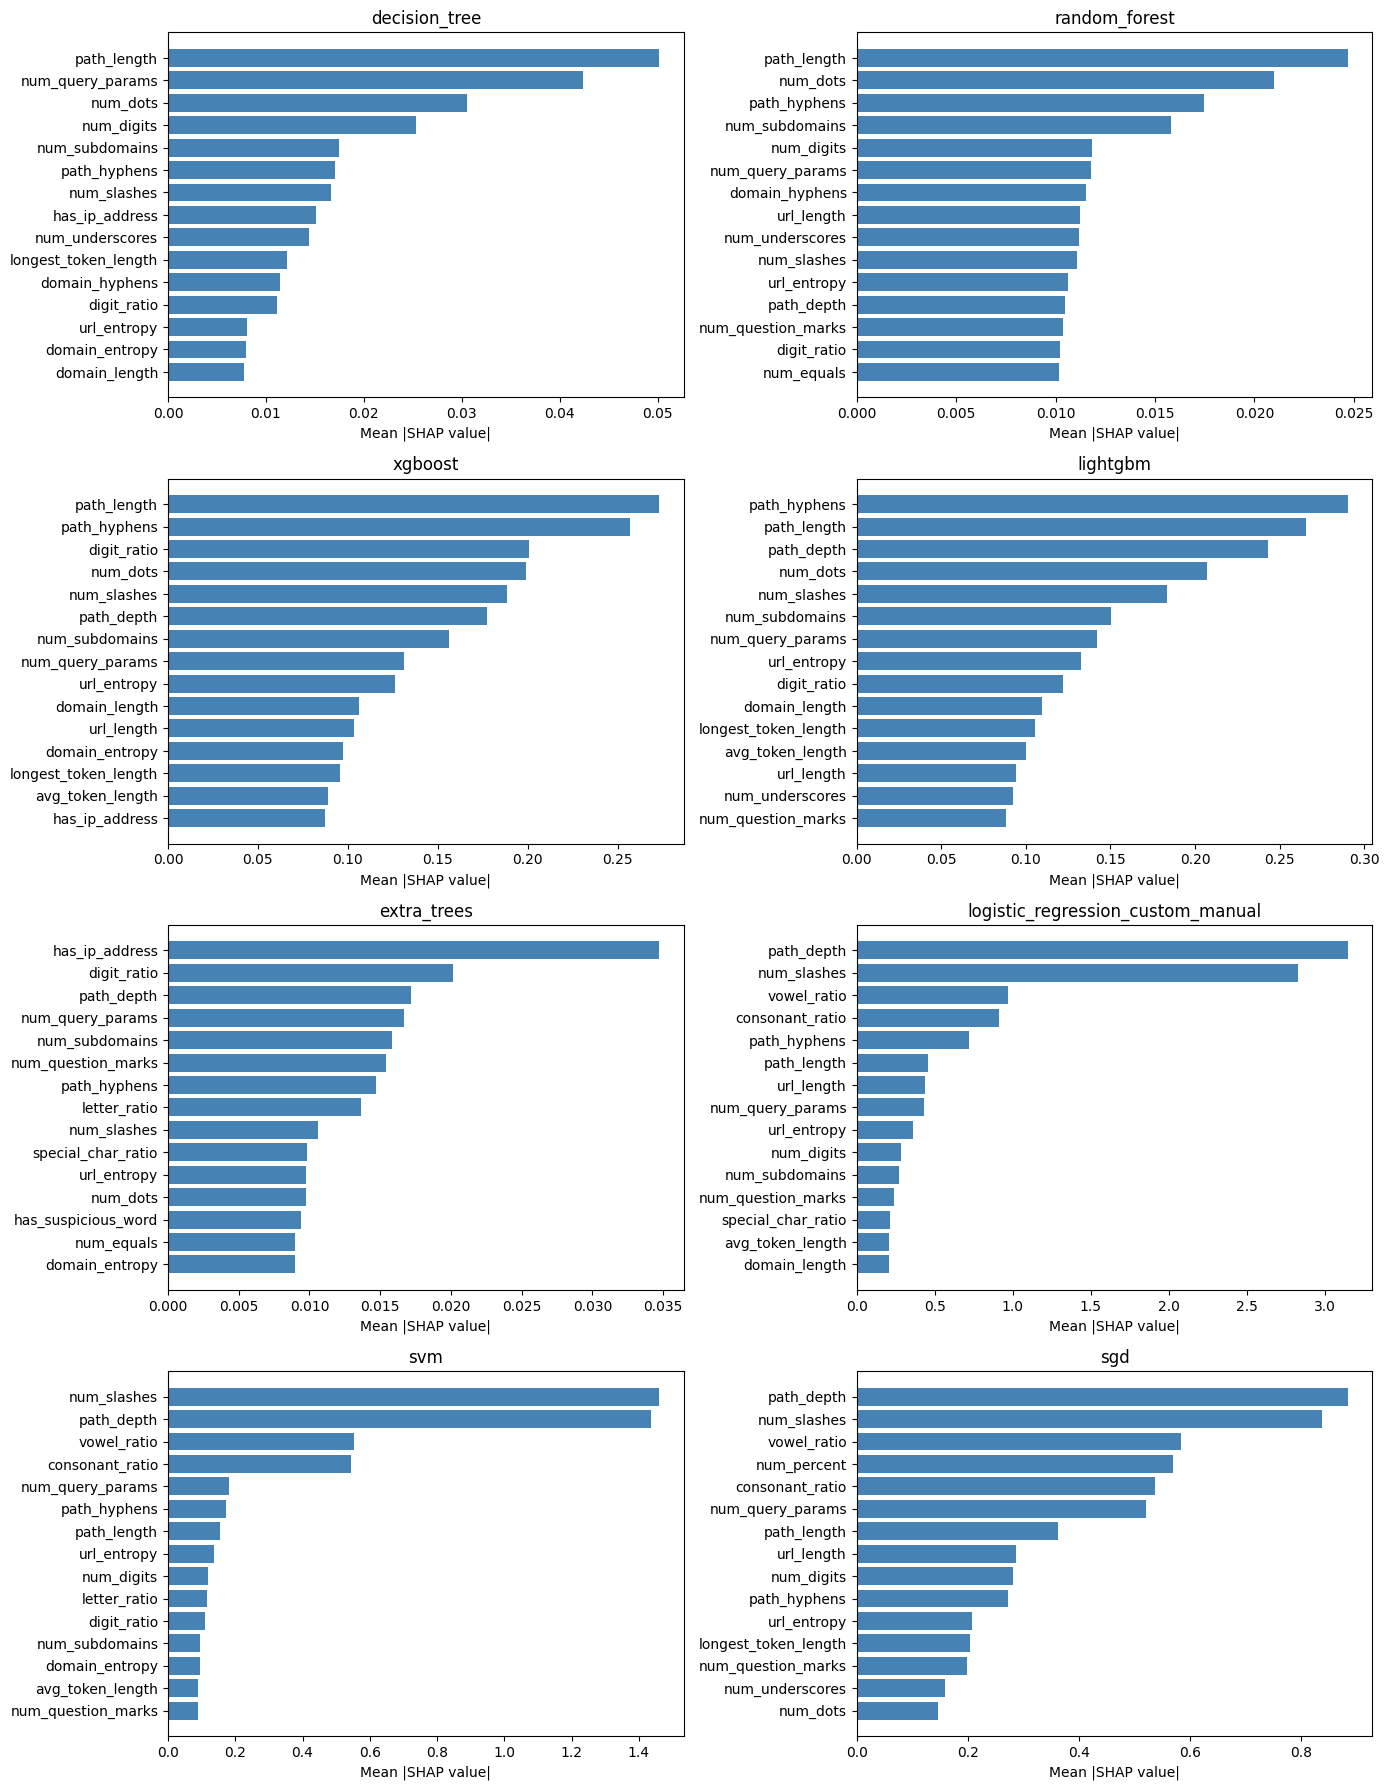

── Top 15 most important features by model ──
           decision_tree       random_forest               xgboost              lightgbm          extra_trees logistic_regression_custom_manual                 svm                   sgd
0            path_length         path_length           path_length          path_hyphens       has_ip_address                        path_depth         num_slashes            path_depth
1       num_query_params            num_dots          path_hyphens           path_length          digit_ratio                       num_slashes          path_depth           num_slashes
2               num_dots        path_hyphens           digit_ratio            path_depth           path_depth                       vowel_ratio         vowel_ratio           vowel_ratio
3             num_digits      num_subdomains              num_dots              num_dots     num_query_params                   consonant_ratio     consonant_ratio           num_percent
4         num_subdomains

In [5]:
# ── 4. Vẽ Global Feature Importance — Mean |SHAP| trung bình qua 4 lớp ──

def mean_abs_shap_per_feature(sv_list):
    stacked = np.stack([np.abs(sv).mean(axis=0) for sv in sv_list], axis=0)  # (n_class, n_feature)
    return stacked.mean(axis=0)  # (n_feature,)

importance_table = {}

fig, axes = plt.subplots(4, 2, figsize=(14, 18))
axes = axes.flatten()

for ax, model_key in zip(axes, shap_values_global.keys()):
    sv_list = shap_values_global[model_key]['values']
    mean_abs = mean_abs_shap_per_feature(sv_list)
    importance_table[model_key] = mean_abs

    order = np.argsort(mean_abs)[::-1][:15]
    ax.barh([FEATURE_COLS[i] for i in order][::-1], mean_abs[order][::-1], color='steelblue')
    ax.set_title(model_key)
    ax.set_xlabel('Mean |SHAP value|')

plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, 'global_feature_importance_all_models.png'), dpi=150)
plt.show()

# ── Bảng so sánh top 15 feature giữa các model ──
importance_df = pd.DataFrame(importance_table, index=FEATURE_COLS)
top15_per_model = pd.DataFrame({
    mk: importance_df[mk].sort_values(ascending=False).head(15).index.tolist()
    for mk in importance_df.columns
})
print("── Top 15 most important features by model ──")
print(top15_per_model.to_string())

## 5. Local Explanation

### 5.1 Tree + Linear Models (8 Models), All Hard Cases

In [6]:
# Local Explanation (Tier 2) — Tree + Linear models, all hard cases 

FORCE_RECOMPUTE_HARD = False  # đổi thành True nếu muốn tính lại toàn bộ từ đầu
CHECKPOINT_PATH = os.path.join(BASE_DIR, 'Reports', 'shap_values_hard_cases.pkl')

# Tự động nạp checkpoint cũ nếu tồn tại -> chỉ tính tiếp các model còn thiếu
if not FORCE_RECOMPUTE_HARD and os.path.exists(CHECKPOINT_PATH):
    shap_values_hard = joblib.load(CHECKPOINT_PATH)
    print(f"Loaded Local SHAP checkpoint ({len(shap_values_hard)} models): {CHECKPOINT_PATH}")
else:
    shap_values_hard = {}

for model_key in TREE_MODELS + LINEAR_MODELS:
    model = models[model_key]
    X_full = get_input(model_key, X_hard, X_hard_scaled)

    # Bỏ qua nếu model đã có trong checkpoint và khớp số mẫu/số feature hiện tại
    if model_key in shap_values_hard:
        cached_sv = shap_values_hard[model_key]
        if len(cached_sv) > 0 and cached_sv[0].shape[:2] == X_full.shape:
            print(f"[SKIP   ] {model_key:35s} → loaded from checkpoint, shape {cached_sv[0].shape}")
            continue
        else:
            print(f"[RECOMPUTE] {model_key:33s} → checkpoint shape mismatch, recomputing...")

    t0 = time.time()
    if model_key in TREE_MODELS:
        explainer = shap.TreeExplainer(model)
        sv = explainer.shap_values(X_full, check_additivity=False)
    else:
        bg_source = get_input(model_key, X_val, X_val_scaled)
        bg_idx = rng.choice(len(bg_source), N_BACKGROUND, replace=False)
        explainer = shap.LinearExplainer(model, bg_source[bg_idx])
        sv = explainer.shap_values(X_full)

    sv_list = sv if isinstance(sv, list) else (
        [sv[:, :, c] for c in range(sv.shape[2])] if sv.ndim == 3 else [sv]
    )

    elapsed = round(time.time() - t0, 1)
    shap_values_hard[model_key] = sv_list
    print(f"[{elapsed:>7}s] {model_key:35s} → {len(sv_list)} class(es), shape {sv_list[0].shape}")

    # Checkpoint — lưu ngay sau mỗi model, tránh mất dữ liệu nếu bị ngắt giữa chừng
    joblib.dump(shap_values_hard, CHECKPOINT_PATH)

print(f"\nCompleted Local SHAP (Tree+Linear) for {len(shap_values_hard)}/{len(TREE_MODELS)+len(LINEAR_MODELS)} models on {len(X_hard)} hard cases")
print(f"Checkpoint: {CHECKPOINT_PATH}")

Loaded Local SHAP checkpoint (8 models): d:\Study Assets\Final Project\PhishingGuard\Reports\shap_values_hard_cases.pkl
[SKIP   ] decision_tree                       → loaded from checkpoint, shape (10836, 32)
[SKIP   ] random_forest                       → loaded from checkpoint, shape (10836, 32)
[SKIP   ] xgboost                             → loaded from checkpoint, shape (10836, 32)
[SKIP   ] lightgbm                            → loaded from checkpoint, shape (10836, 32)
[SKIP   ] extra_trees                         → loaded from checkpoint, shape (10836, 32)
[SKIP   ] logistic_regression_custom_manual   → loaded from checkpoint, shape (10836, 32)
[SKIP   ] svm                                 → loaded from checkpoint, shape (10836, 32)
[SKIP   ] sgd                                 → loaded from checkpoint, shape (10836, 32)

Completed Local SHAP (Tree+Linear) for 8/8 models on 10836 hard cases
Checkpoint: d:\Study Assets\Final Project\PhishingGuard\Reports\shap_values_hard_cases.pk

### 5.2 KernelExplainer Speed Benchmark

In [7]:
# ── 6. Local Explanation (Tier 2) — Kernel-based: TEST tốc độ trước khi chạy full ──

N_TEST = 20
N_KMEANS_BACKGROUND = 50

for model_key in KERNEL_MODELS:
    model = models[model_key]
    X_full  = get_input(model_key, X_hard, X_hard_scaled)
    X_test  = X_full[:N_TEST]

    bg_source  = get_input(model_key, X_val, X_val_scaled)
    background = shap.kmeans(bg_source, N_KMEANS_BACKGROUND)

    predict_fn = model.predict_proba if hasattr(model, 'predict_proba') else model.decision_function
    explainer  = shap.KernelExplainer(predict_fn, background)

    t0 = time.time()
    sv_test = explainer.shap_values(X_test, nsamples=200)
    elapsed = time.time() - t0

    per_sample     = elapsed / N_TEST
    projected_full = per_sample * len(X_hard)

    print(f"{model_key:10s} — {N_TEST} samples: {elapsed:.1f}s, {per_sample:.2f}s/sample")
    print(f"  → Estimated time for FULL {len(X_hard)} hard cases: "
          f"{projected_full/60:.1f} min (~{projected_full/3600:.2f} hours)\n")

100%|██████████| 20/20 [00:16<00:00,  1.21it/s]


bagging    — 20 samples: 16.5s, 0.83s/sample
  → Estimated time for FULL 10836 hard cases: 149.4 min (~2.49 hours)



100%|██████████| 20/20 [00:46<00:00,  2.34s/it]

knn        — 20 samples: 46.8s, 2.34s/sample
  → Estimated time for FULL 10836 hard cases: 423.0 min (~7.05 hours)



### 5.3 Stratified Sample of 2,500 Hard Cases

In [8]:
from sklearn.model_selection import train_test_split

N_KERNEL_SAMPLE = min(2500, len(hard_cases) - 10)

kernel_idx, _ = train_test_split(
    np.arange(len(hard_cases)),
    train_size=N_KERNEL_SAMPLE,
    stratify=hard_cases['Label'],
    random_state=42
)

hard_cases_kernel    = hard_cases.iloc[kernel_idx].reset_index(drop=True)
X_hard_kernel        = X_hard[kernel_idx]
X_hard_kernel_scaled = X_hard_scaled[kernel_idx]

print(f"Stratified sample for Kernel-based SHAP: {len(kernel_idx)}/{len(hard_cases)} hard cases")
print(hard_cases_kernel['Label'].value_counts())

Stratified sample for Kernel-based SHAP: 2500/10836 hard cases
Label
phishing      1252
defacement     635
benign         471
malware        142
Name: count, dtype: int64


### 5.4 Run Full Kernel SHAP for Bagging + kNN on 2,500 Samples

In [9]:
N_KMEANS_BACKGROUND = 50
FORCE_RECOMPUTE_KERNEL = False  # đổi thành True nếu muốn tính lại toàn bộ từ đầu
CHECKPOINT_KERNEL_PATH = os.path.join(BASE_DIR, 'Reports', 'shap_values_kernel_hard_cases.pkl')

# Tự động nạp checkpoint cũ nếu tồn tại -> chỉ tính tiếp các model còn thiếu
if not FORCE_RECOMPUTE_KERNEL and os.path.exists(CHECKPOINT_KERNEL_PATH):
    shap_values_kernel = joblib.load(CHECKPOINT_KERNEL_PATH)
    print(f"Loaded Kernel SHAP checkpoint ({len(shap_values_kernel)} models): {CHECKPOINT_KERNEL_PATH}")
else:
    shap_values_kernel = {}

for model_key in KERNEL_MODELS:   # ['bagging', 'knn'] — bagging chạy trước (nhanh hơn, quan trọng hơn)
    model = models[model_key]
    X_full = get_input(model_key, X_hard_kernel, X_hard_kernel_scaled)

    # Bỏ qua nếu model đã có trong checkpoint và khớp số mẫu/số feature hiện tại
    if model_key in shap_values_kernel:
        cached_sv = shap_values_kernel[model_key]
        if len(cached_sv) > 0 and cached_sv[0].shape[:2] == X_full.shape:
            print(f"[SKIP] {model_key:20s} → loaded from checkpoint, shape {cached_sv[0].shape}")
            continue
        else:
            print(f"[RECOMPUTE] {model_key:15s} → checkpoint shape mismatch, recomputing...")

    bg_source  = get_input(model_key, X_val, X_val_scaled)
    background = shap.kmeans(bg_source, N_KMEANS_BACKGROUND)

    predict_fn = model.predict_proba if hasattr(model, 'predict_proba') else model.decision_function
    explainer  = shap.KernelExplainer(predict_fn, background)

    print(f"\n── Running {model_key} on {len(X_full)} samples ──")
    t0 = time.time()
    sv = explainer.shap_values(X_full, nsamples=200)
    elapsed = time.time() - t0

    sv_list = sv if isinstance(sv, list) else [sv]
    shap_values_kernel[model_key] = sv_list

    print(f"[{elapsed:.1f}s ({elapsed/60:.1f} min)] {model_key} completed, shape {sv_list[0].shape}")

    joblib.dump(shap_values_kernel, CHECKPOINT_KERNEL_PATH)  # checkpoint ngay sau mỗi model
    print("  Checkpoint saved")

print(f"\nCompleted Local SHAP (Kernel-based) for {len(shap_values_kernel)}/{len(KERNEL_MODELS)} models")

Loaded Kernel SHAP checkpoint (1 models): d:\Study Assets\Final Project\PhishingGuard\Reports\shap_values_kernel_hard_cases.pkl
[SKIP] bagging              → loaded from checkpoint, shape (2500, 32, 4)

── Running knn on 2500 samples ──


100%|██████████| 2500/2500 [1:38:00<00:00,  2.35s/it]

[5880.7s (98.0 min)] knn completed, shape (2500, 32, 4)
  Checkpoint saved

Completed Local SHAP (Kernel-based) for 2/2 models


In [10]:
# ── Chuẩn hóa lại shap_values_kernel về đúng định dạng list-per-class (giống các model khác) ──

for model_key in list(shap_values_kernel.keys()):
    sv = shap_values_kernel[model_key]
    current = sv[0] if isinstance(sv, list) and len(sv) == 1 else sv

    if hasattr(current, 'ndim') and current.ndim == 3:
        sv_list = [current[:, :, c] for c in range(current.shape[2])]
        shap_values_kernel[model_key] = sv_list
        print(f"{model_key}: normalized → {len(sv_list)} class(es), shape {sv_list[0].shape}")
    else:
        print(f"{model_key}: already in valid format, kept as-is")

# Lưu đè lại checkpoint với định dạng đã chuẩn hóa
joblib.dump(shap_values_kernel, CHECKPOINT_KERNEL_PATH)
print("\nCheckpoint updated")

bagging: normalized → 4 class(es), shape (2500, 32)
knn: normalized → 4 class(es), shape (2500, 32)

Checkpoint updated


## 6. Predictions of All 10 Models on Hard Cases

In [11]:
# ── Predictions trên hard cases — biết model đoán SAI THÀNH LỚP NÀO ──
y_pred_hard = {}

for model_key in TREE_MODELS + LINEAR_MODELS:
    model = models[model_key]
    X_full = get_input(model_key, X_hard, X_hard_scaled)
    y_pred_hard[model_key] = model.predict(X_full)

for model_key in KERNEL_MODELS:
    model = models[model_key]
    X_full = get_input(model_key, X_hard_kernel, X_hard_kernel_scaled)
    y_pred_hard[model_key] = model.predict(X_full)

print("Done!")

Done!


### 6.1 Compare Feature Importance: Hard Cases (Tier 2) vs Global Val Set (Tier 1)

In [12]:
def mean_abs_shap(sv_list):
    return np.stack([np.abs(sv).mean(axis=0) for sv in sv_list], axis=0).mean(axis=0)

comparison_rows = []
for model_key in TREE_MODELS + LINEAR_MODELS:
    imp_normal = mean_abs_shap(shap_values_global[model_key]['values'])
    imp_hard   = mean_abs_shap(shap_values_hard[model_key])
    top_normal = FEATURE_COLS[np.argmax(imp_normal)]
    top_hard   = FEATURE_COLS[np.argmax(imp_hard)]
    comparison_rows.append({'model': model_key, 'top_feature_normal': top_normal, 'top_feature_hard_case': top_hard,
                             'changed': top_normal != top_hard})

for model_key in KERNEL_MODELS:
    imp_hard = mean_abs_shap(shap_values_kernel[model_key])
    top_hard = FEATURE_COLS[np.argmax(imp_hard)]
    comparison_rows.append({'model': model_key, 'top_feature_normal': '(N/A in Tier 1)', 'top_feature_hard_case': top_hard,
                             'changed': None})

comparison_df = pd.DataFrame(comparison_rows)
print("── Most Important Feature: Normal (Tier 1) vs Misclassified Hard Cases (Tier 2) ──")
print(comparison_df.to_string(index=False))

── Most Important Feature: Normal (Tier 1) vs Misclassified Hard Cases (Tier 2) ──
                            model top_feature_normal top_feature_hard_case changed
                    decision_tree        path_length           path_length   False
                    random_forest        path_length           path_length   False
                          xgboost        path_length           path_length   False
                         lightgbm       path_hyphens          path_hyphens   False
                      extra_trees     has_ip_address        has_ip_address   False
logistic_regression_custom_manual         path_depth            path_depth   False
                              svm        num_slashes            path_depth    True
                              sgd         path_depth            path_depth   False
                          bagging    (N/A in Tier 1)           path_length    None
                              knn    (N/A in Tier 1)        num_subdomains    None


### 6.2 Inspect Worst Misclassified Case

In [13]:
worst_case_idx = hard_cases['n_models_wrong'].idxmax()
worst_case = hard_cases.loc[worst_case_idx]

print(f"URL: {worst_case['URL']}")
print(f"True label: {worst_case['Label']}  |  {worst_case['n_models_wrong']}/{worst_case['n_models_total']} models wrong\n")

for model_key in ['random_forest', 'logistic_regression_custom_manual', 'bagging']:
    if model_key in KERNEL_MODELS:
        if worst_case_idx in kernel_idx:
            k_pos = list(kernel_idx).index(worst_case_idx)
            pred = y_pred_hard[model_key][k_pos]
        else:
            pred = models[model_key].predict(get_input(model_key, X_hard[[worst_case_idx]], X_hard_scaled[[worst_case_idx]]))[0]
    else:
        pred = y_pred_hard[model_key][worst_case_idx]
    print(f"{model_key:35s} → predicted: {LABEL_NAMES[pred]}")

URL: http://stumbleupon.com/submit?url=http://www.greeteasy.com/happy-ganesh-chaturthi-1/
True label: malware  |  16/16 models wrong

random_forest                       → predicted: benign
logistic_regression_custom_manual   → predicted: phishing
bagging                             → predicted: benign


### 6.3 Waterfall Plots for Worst Case (3 Representative Models: Tree, Linear, Kernel)


── random_forest — Explanation for predicting 'benign' (true: 'phishing') ──


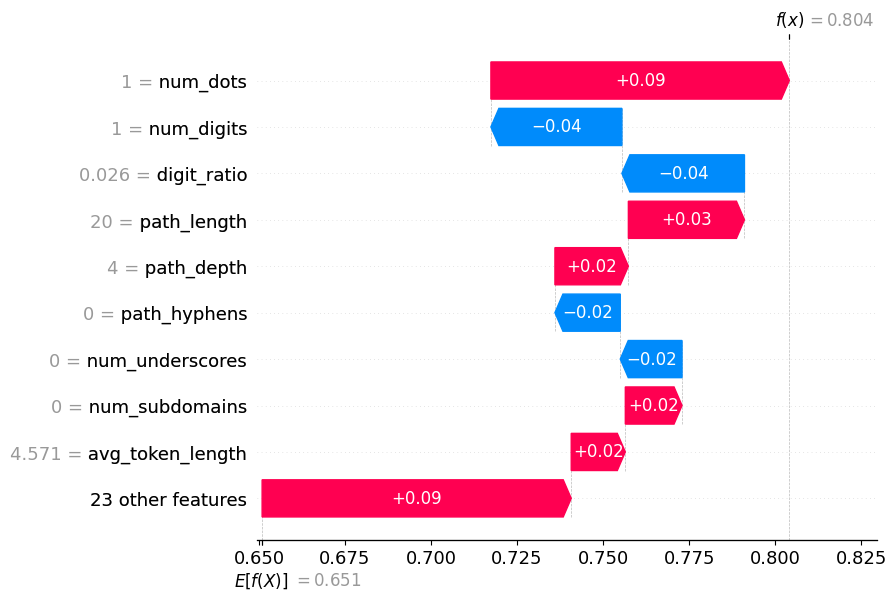

Background dataset has 200 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=200 when initializing the masker.



── logistic_regression_custom_manual — Explanation for predicting 'benign' (true: 'phishing') ──


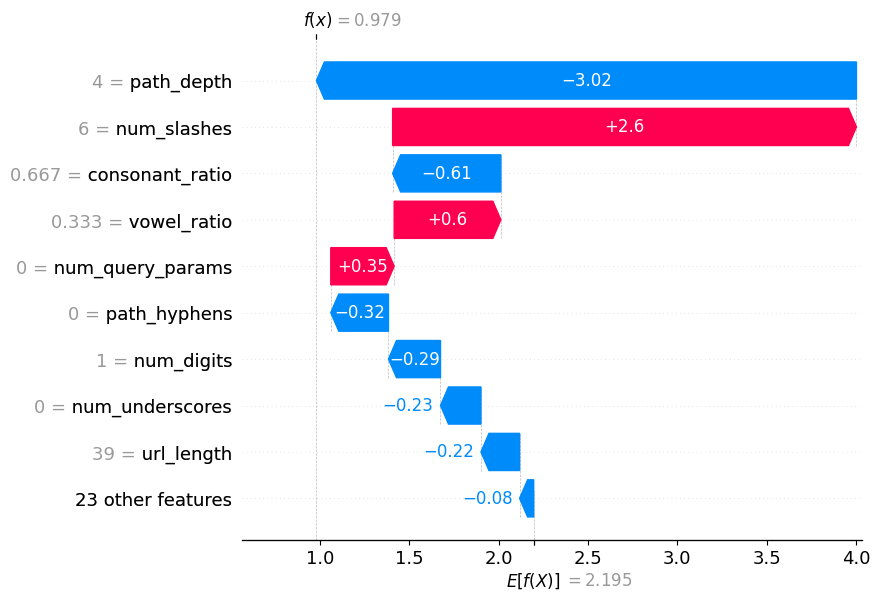


── bagging — Explanation for predicting 'benign' (true: 'phishing') ──


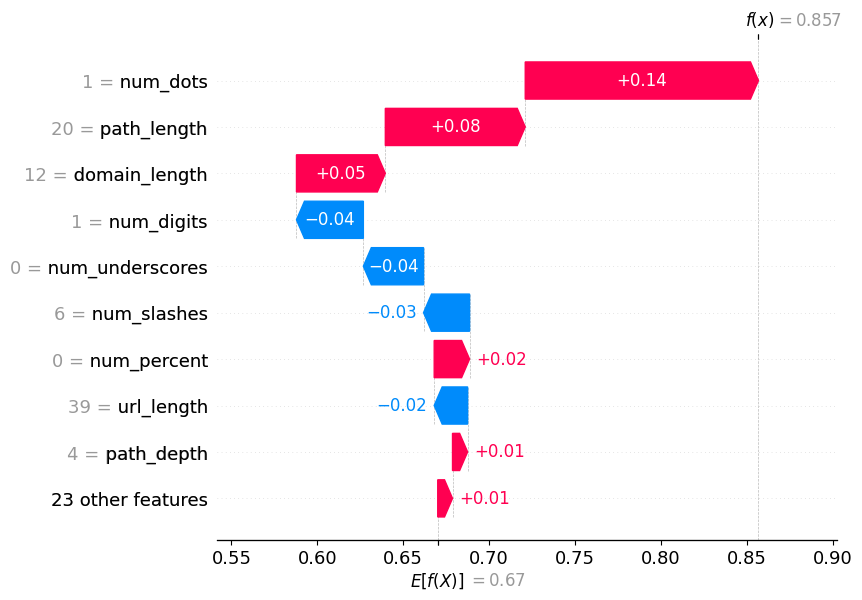

In [14]:
import shap as shap_lib

# Chọn 1 mẫu nằm trong cả tập kernel_idx để vẽ đủ 3 model
worst_in_kernel_pos = int(np.argmax(hard_cases_kernel['n_models_wrong'].values))
worst_full_idx      = int(kernel_idx[worst_in_kernel_pos])
worst_case          = hard_cases.loc[worst_full_idx]

def get_expected_value(model_key):
    model = models[model_key]
    if model_key in TREE_MODELS:
        return shap.TreeExplainer(model).expected_value
    elif model_key in LINEAR_MODELS:
        bg = get_input(model_key, X_val, X_val_scaled)
        bg_idx = rng.choice(len(bg), N_BACKGROUND, replace=False)
        return shap.LinearExplainer(model, bg[bg_idx]).expected_value
    else:
        bg = shap.kmeans(get_input(model_key, X_val, X_val_scaled), N_KMEANS_BACKGROUND)
        predict_fn = model.predict_proba if hasattr(model, 'predict_proba') else model.decision_function
        return shap.KernelExplainer(predict_fn, bg).expected_value

for model_key in ['random_forest', 'logistic_regression_custom_manual', 'bagging']:
    row_idx = worst_full_idx if model_key not in KERNEL_MODELS else worst_in_kernel_pos
    sv_dict = shap_values_hard if model_key not in KERNEL_MODELS else shap_values_kernel
    X_data  = X_hard if model_key not in KERNEL_MODELS else X_hard_kernel

    pred_class = y_pred_hard[model_key][row_idx]
    expected_val = get_expected_value(model_key)
    ev = expected_val[pred_class] if hasattr(expected_val, '__len__') else expected_val

    explanation = shap.Explanation(
        values=sv_dict[model_key][pred_class][row_idx],
        base_values=ev,
        data=X_data[row_idx],
        feature_names=FEATURE_COLS
    )
    print(f"\n── {model_key} — Explanation for predicting '{LABEL_NAMES[pred_class]}' (true: '{worst_case['Label']}') ──")
    shap.plots.waterfall(explanation, show=False)
    plt.savefig(os.path.join(IMAGES_DIR, f'waterfall_{model_key}_worst_case.png'), dpi=150, bbox_inches='tight')
    plt.show()

## 7. Feature Selection Based on SHAP Global Importance (Tier 1)

── Consensus Feature Ranking Across 8 Models (SHAP Tier 1) ──
                      mean_rank  mean_norm_shap  n_models_top10  rank_std
path_hyphens               5.00          0.0580               8      2.93
num_slashes                5.12          0.1019               8      3.36
path_length                5.25          0.0692               7      5.47
path_depth                 5.62          0.1062               6      5.85
num_query_params           5.75          0.0560               8      2.05
num_subdomains             8.38          0.0396               5      4.53
num_dots                   9.00          0.0474               4      6.30
url_entropy               10.00          0.0324               4      1.77
digit_ratio               12.12          0.0353               3      7.97
num_digits                12.25          0.0329               5      7.32
url_length                13.62          0.0279               3      6.19
consonant_ratio           14.00          0.0425   

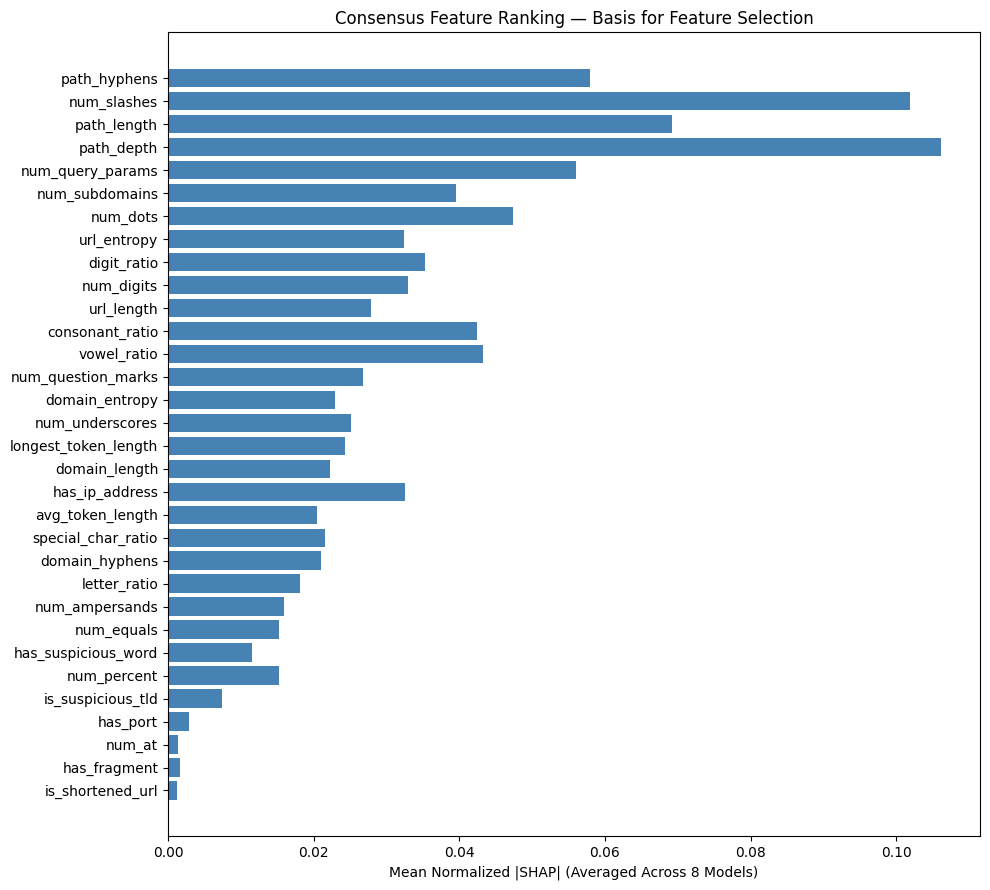

In [15]:
def mean_abs_shap(sv_list):
    return np.stack([np.abs(sv).mean(axis=0) for sv in sv_list], axis=0).mean(axis=0)

rank_table, norm_table = {}, {}
for model_key, info in shap_values_global.items():
    imp = mean_abs_shap(info['values'])
    norm_table[model_key] = imp / imp.sum()                                   # tỉ lệ đóng góp (chuẩn hoá thang đo)
    rank_table[model_key] = pd.Series(imp, index=FEATURE_COLS).rank(ascending=False)

rank_df = pd.DataFrame(rank_table, index=FEATURE_COLS)
norm_df = pd.DataFrame(norm_table, index=FEATURE_COLS)

consensus = pd.DataFrame({
    'mean_rank':      rank_df.mean(axis=1).round(2),
    'mean_norm_shap': norm_df.mean(axis=1).round(4),
    'n_models_top10': (rank_df <= 10).sum(axis=1),
    'rank_std':       rank_df.std(axis=1).round(2),      # độ bất đồng giữa các model
}).sort_values('mean_rank')

FEATURE_RANKING = consensus.index.tolist()

print(f"── Consensus Feature Ranking Across {len(shap_values_global)} Models (SHAP Tier 1) ──")
print(consensus.to_string())

plt.figure(figsize=(10, 9))
plt.barh(consensus.index[::-1], consensus['mean_norm_shap'][::-1], color='steelblue')
plt.xlabel('Mean Normalized |SHAP| (Averaged Across 8 Models)')
plt.title('Consensus Feature Ranking — Basis for Feature Selection')
plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, 'feature_ranking_consensus.png'), dpi=150)
plt.show()

### 7.1 Configuration & Base Model Hyperparameters

In [16]:
import json
from sklearn.base import clone
from sklearn.metrics import f1_score, accuracy_score, recall_score, classification_report
 
BENIGN_IDX = label_to_idx['benign']
CLASSES    = list(range(len(LABEL_NAMES)))
 
N_FEAT_ALL   = len(FEATURE_COLS)   # 32 feature (đã tách domain_hyphens và path_hyphens)
K_LIST       = [5, 8, 10, 12, 15, 20, 25, N_FEAT_ALL]
TOLERANCE    = 0.99    # giữ >= 99% macro-F1 của bản đủ feature
RECALL_TOL   = 0.02    # không lớp nào được tụt recall quá 2 điểm % so với bản đủ feature
N_BOOT       = 300     # số lần bootstrap trên val để ước lượng độ nhiễu
SELECT_MODELS = ['lightgbm', 'xgboost', 'decision_tree']
 
# Clone từ chính model đã train trong modeling.ipynb => hyperparameter KHỚP bản gốc
base_models = {k: joblib.load(os.path.join(MODELS_DIR, 'merged', f'{k}.pkl')) for k in SELECT_MODELS}
for k, m in base_models.items():
    print(k, m.get_params(), '\n')

lightgbm {'boosting_type': 'gbdt', 'class_weight': None, 'colsample_bytree': 1.0, 'importance_type': 'split', 'learning_rate': 0.1, 'max_depth': -1, 'min_child_samples': 20, 'min_child_weight': 0.001, 'min_split_gain': 0.0, 'n_estimators': 100, 'n_jobs': -1, 'num_leaves': 31, 'objective': 'multiclass', 'random_state': 42, 'reg_alpha': 0.0, 'reg_lambda': 0.0, 'subsample': 1.0, 'subsample_for_bin': 200000, 'subsample_freq': 0, 'num_class': 4, 'verbose': -1} 

xgboost {'objective': 'multi:softprob', 'base_score': None, 'booster': None, 'callbacks': None, 'colsample_bylevel': None, 'colsample_bynode': None, 'colsample_bytree': None, 'device': None, 'early_stopping_rounds': None, 'enable_categorical': True, 'eval_metric': 'mlogloss', 'feature_types': None, 'feature_weights': None, 'gamma': None, 'grow_policy': None, 'importance_type': None, 'interaction_constraints': None, 'learning_rate': 0.1, 'max_bin': None, 'max_cat_threshold': None, 'max_cat_to_onehot': None, 'max_delta_step': None, 'm

### 7.2 Load Training Data

In [17]:
train = pd.read_csv(os.path.join(TRAIN_TEST_DIR, 'merged', 'train.csv'))
X_train_all = train[FEATURE_COLS].values
y_train_all = train['Label'].map(label_to_idx).values
print(X_train_all.shape, y_train_all.shape)   # kỳ vọng: (n_train, 32) (n_train,)

(484379, 32) (484379,)


### 7.3 Retrain Models Across Top-k Feature Subsets & Predict on Val

In [18]:
val_pred = {}
for name, base in base_models.items():
    for k in K_LIST:
        idx = [FEATURE_COLS.index(c) for c in FEATURE_RANKING[:k]]
        m = clone(base)
        m.fit(X_train_all[:, idx], y_train_all)
        val_pred[(name, k)] = m.predict(X_val[:, idx])
        print(f"done {name:14s} k={k:2d}")

done lightgbm       k= 5
done lightgbm       k= 8
done lightgbm       k=10
done lightgbm       k=12
done lightgbm       k=15
done lightgbm       k=20
done lightgbm       k=25
done lightgbm       k=32
done xgboost        k= 5
done xgboost        k= 8
done xgboost        k=10
done xgboost        k=12
done xgboost        k=15
done xgboost        k=20
done xgboost        k=25
done xgboost        k=32
done decision_tree  k= 5
done decision_tree  k= 8
done decision_tree  k=10
done decision_tree  k=12
done decision_tree  k=15
done decision_tree  k=20
done decision_tree  k=25
done decision_tree  k=32


### 7.4 Compute Metrics (Macro-F1, Accuracy, Per-Class Recall, Benign FPR)

In [19]:
def metrics(y_true, y_pred):
    rec = recall_score(y_true, y_pred, labels=CLASSES, average=None, zero_division=0)
    d = {
        'acc': accuracy_score(y_true, y_pred),
        'macro_f1': f1_score(y_true, y_pred, average='macro'),
        'benign_fpr': float(np.mean(y_pred[y_true == BENIGN_IDX] != BENIGN_IDX)),  # benign bị chặn nhầm
    }
    d.update({f'recall_{LABEL_NAMES[c]}': rec[c] for c in CLASSES})
    return d
 
res = pd.DataFrame([{'model': n, 'k': k, **metrics(y_val, yp)} for (n, k), yp in val_pred.items()])
res.to_csv(os.path.join(MODELS_DIR, 'feature_selection_results_v2.csv'), index=False)
 
full = res[res.k == max(K_LIST)].set_index('model')
res['f1_ratio'] = res.apply(lambda r: r.macro_f1 / full.loc[r.model, 'macro_f1'], axis=1)
 
print(f"Macro-F1 ratio compared to k={max(K_LIST)}:")
print(res.pivot(index='k', columns='model', values='f1_ratio').round(4))
print("Per-class Recall (LightGBM):")
print(res[res.model == 'lightgbm'].set_index('k')[[c for c in res.columns if c.startswith('recall_')]].round(4))

Macro-F1 ratio compared to k=32:
model  decision_tree  lightgbm  xgboost
k                                      
5             0.7080    0.6751   0.6756
8             0.9272    0.9036   0.9043
10            0.9645    0.9361   0.9399
12            0.9807    0.9551   0.9621
15            0.9944    0.9683   0.9751
20            0.9879    0.9883   0.9922
25            0.9963    0.9936   0.9986
32            1.0000    1.0000   1.0000
Per-class Recall (LightGBM):
    recall_benign  recall_defacement  recall_malware  recall_phishing
k                                                                    
5          0.9671             0.4625          0.3128           0.1903
8          0.9275             0.5667          0.7505           0.4577
10         0.9478             0.6278          0.7968           0.4183
12         0.9447             0.6494          0.8019           0.4626
15         0.9483             0.6564          0.8236           0.4739
20         0.9443             0.6991          0.

### 7.5 Bootstrap 95% Confidence Intervals for Δ Macro-F1

In [20]:
rng_b = np.random.RandomState(0)
boot_idx = rng_b.randint(0, len(y_val), size=(N_BOOT, len(y_val))).astype(np.int32)
 
ci_rows = []
for name in SELECT_MODELS:
    ref = val_pred[(name, max(K_LIST))]
    for k in K_LIST[:-1]:
        a = val_pred[(name, k)]
        d = [f1_score(y_val[b], a[b], average='macro') - f1_score(y_val[b], ref[b], average='macro')
             for b in boot_idx]
        lo, hi = np.percentile(d, [2.5, 97.5])
        ci_rows.append({'model': name, 'k': k, 'delta_f1_mean': np.mean(d), 'ci_low': lo, 'ci_high': hi})
ci_df = pd.DataFrame(ci_rows)
print(f"Δ Macro-F1 (k vs {max(K_LIST)}) with 95% CI:")
print(ci_df.round(4))

Δ Macro-F1 (k vs 32) with 95% CI:
            model   k  delta_f1_mean  ci_low  ci_high
0        lightgbm   5        -0.2606 -0.2657  -0.2553
1        lightgbm   8        -0.0774 -0.0803  -0.0744
2        lightgbm  10        -0.0513 -0.0537  -0.0490
3        lightgbm  12        -0.0361 -0.0386  -0.0336
4        lightgbm  15        -0.0254 -0.0276  -0.0232
5        lightgbm  20        -0.0095 -0.0111  -0.0077
6        lightgbm  25        -0.0052 -0.0067  -0.0038
7         xgboost   5        -0.2617 -0.2671  -0.2566
8         xgboost   8        -0.0772 -0.0801  -0.0744
9         xgboost  10        -0.0485 -0.0506  -0.0462
10        xgboost  12        -0.0306 -0.0325  -0.0287
11        xgboost  15        -0.0201 -0.0219  -0.0184
12        xgboost  20        -0.0063 -0.0080  -0.0047
13        xgboost  25        -0.0011 -0.0024   0.0003
14  decision_tree   5        -0.2279 -0.2331  -0.2230
15  decision_tree   8        -0.0567 -0.0598  -0.0534
16  decision_tree  10        -0.0276 -0.0305  -0

### 7.6 Select Optimal k Across All 3 Models (+ Force Keep Domain-Knowledge Features)

In [21]:
recall_cols = [c for c in res.columns if c.startswith('recall_')]
 
def passes(row):
    f = full.loc[row.model]
    f1_ok  = row.macro_f1 >= f.macro_f1 * TOLERANCE
    rec_ok = all((f[c] - row[c]) <= RECALL_TOL for c in recall_cols)
    return f1_ok and rec_ok
 
res['pass'] = res.apply(passes, axis=1)
pass_by_k = res.groupby('k')['pass'].all()
print("k satisfying criteria across ALL 3 models:")
print(pass_by_k.to_string())
 
k_opt = int(pass_by_k[pass_by_k].index.min()) if pass_by_k.any() else max(K_LIST)
SELECTED_FEATURES = list(FEATURE_RANKING[:k_opt])
# Đảm bảo luôn giữ lại 3 đặc trưng chuyên môn (precision cao với phishing hiện đại) nếu lỡ nằm ngoài top k_opt
for must_keep in ['domain_hyphens', 'is_suspicious_tld', 'has_suspicious_word']:
    if must_keep in FEATURE_COLS and must_keep not in SELECTED_FEATURES:
        SELECTED_FEATURES.append(must_keep)

removed = [f for f in FEATURE_COLS if f not in SELECTED_FEATURES]
print(f"\nOptimal k (SHAP) = {k_opt} | Total selected features = {len(SELECTED_FEATURES)}/{N_FEAT_ALL} (reduced by {(N_FEAT_ALL - len(SELECTED_FEATURES)) / N_FEAT_ALL * 100:.0f}%)")
print("Selected features:", SELECTED_FEATURES)
print("Dropped features :", removed)

k satisfying criteria across ALL 3 models:
k
5     False
8     False
10    False
12    False
15    False
20    False
25     True
32     True

Optimal k (SHAP) = 25 | Total selected features = 27/32 (reduced by 16%)
Selected features: ['path_hyphens', 'num_slashes', 'path_length', 'path_depth', 'num_query_params', 'num_subdomains', 'num_dots', 'url_entropy', 'digit_ratio', 'num_digits', 'url_length', 'consonant_ratio', 'vowel_ratio', 'num_question_marks', 'domain_entropy', 'num_underscores', 'longest_token_length', 'domain_length', 'has_ip_address', 'avg_token_length', 'special_char_ratio', 'domain_hyphens', 'letter_ratio', 'num_ampersands', 'num_equals', 'is_suspicious_tld', 'has_suspicious_word']
Dropped features : ['num_at', 'num_percent', 'has_port', 'has_fragment', 'is_shortened_url']


### 7.7 Feature Selection Curve & Export Final Features JSON

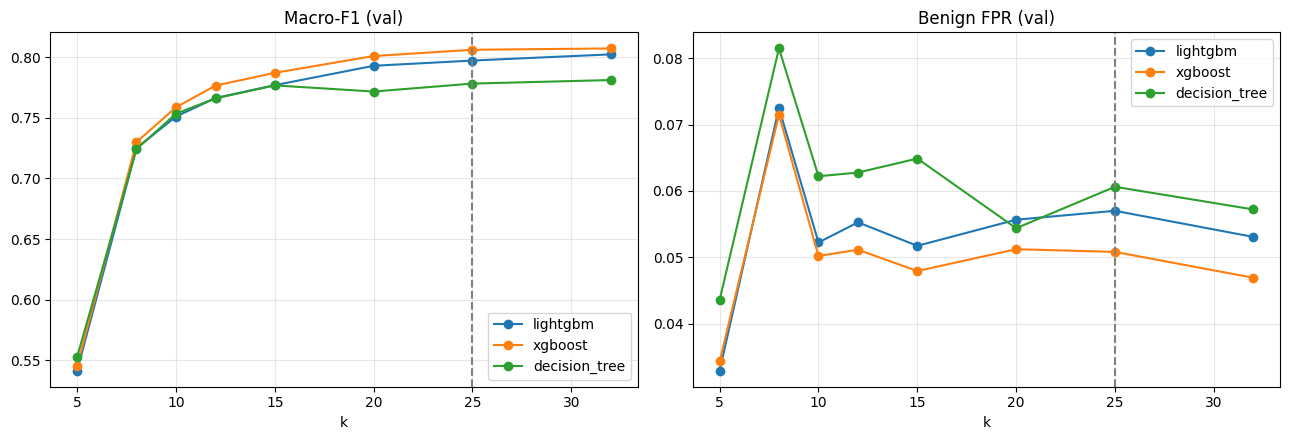

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name in SELECT_MODELS:
    sub = res[res.model == name].sort_values('k')
    axes[0].plot(sub.k, sub.macro_f1, marker='o', label=name)
    axes[1].plot(sub.k, sub.benign_fpr, marker='o', label=name)
for ax, t in zip(axes, ['Macro-F1 (val)', 'Benign FPR (val)']):
    ax.axvline(k_opt, ls='--', c='gray'); ax.set_title(t); ax.set_xlabel('k'); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, 'feature_selection_curve_v2.png'), dpi=150)
plt.show()
 
with open(os.path.join(MODELS_DIR, 'final_features.json'), 'w', encoding='utf-8') as f:
    json.dump({'k': len(SELECTED_FEATURES), 'k_shap': k_opt, 'features': SELECTED_FEATURES, 'dropped': removed}, f, indent=2, ensure_ascii=False)

## 8. Final Evaluation & Threshold Optimization

In [23]:
from sklearn.model_selection import train_test_split

idx = [FEATURE_COLS.index(c) for c in SELECTED_FEATURES]

# 1. Model chốt: train trên TRAIN, KHÔNG retrain cùng val
lgbm = clone(base_models['lightgbm']).fit(X_train_all[:, idx], y_train_all)

# 2. Chia val thành A (chọn ngưỡng) và B (báo kết quả)
ia, ib = train_test_split(np.arange(len(y_val)), test_size=0.5,
                          stratify=y_val, random_state=0)
X_a, y_a = X_val[ia][:, idx], y_val[ia]
X_b, y_b = X_val[ib][:, idx], y_val[ib]

def mal_score(model, X):
    return 1.0 - model.predict_proba(X)[:, BENIGN_IDX]

def thr_metrics(y_true, score, tau):
    is_mal = y_true != BENIGN_IDX
    flag = score >= tau
    fpr = flag[~is_mal].mean()
    tpr = flag[is_mal].mean()
    prec = is_mal[flag].mean() if flag.any() else np.nan
    return fpr, tpr, prec

# 3. Chọn tau trên A: TPR lớn nhất với FPR <= mục tiêu
FPR_TARGET = 0.01
s_a = mal_score(lgbm, X_a)
sweep = pd.DataFrame([(t, *thr_metrics(y_a, s_a, t))
                      for t in np.linspace(0.05, 0.95, 91)],
                     columns=['tau', 'fpr', 'tpr', 'prec'])
cand = sweep[sweep.fpr <= FPR_TARGET]
tau_opt = float(cand.sort_values('tpr', ascending=False).iloc[0].tau)
print(f"tau_opt (selected on Split A) = {tau_opt:.2f}")

# 4. Báo kết quả trên B
pred_b = lgbm.predict(X_b)
print("=== Split B: Default Argmax ===")
print(classification_report(y_b, pred_b, target_names=LABEL_NAMES, digits=4))
print("Benign FPR (argmax):", round((pred_b[y_b == BENIGN_IDX] != BENIGN_IDX).mean(), 4))

s_b = mal_score(lgbm, X_b)
fpr, tpr, prec = thr_metrics(y_b, s_b, tau_opt)
print(f"=== Split B: Threshold tau={tau_opt:.2f} === FPR={fpr:.4f} | TPR={tpr:.4f} | precision={prec:.4f}")

# 5. Khoảng tin cậy bootstrap cho FPR và TPR trên B
rng = np.random.default_rng(0)
boots = []
for _ in range(300):
    i = rng.integers(0, len(y_b), len(y_b))
    boots.append(thr_metrics(y_b[i], s_b[i], tau_opt)[:2])
lo, hi = np.percentile(np.array(boots), [2.5, 97.5], axis=0)
print(f"FPR 95% CI: [{lo[0]:.4f}, {hi[0]:.4f}] | TPR 95% CI: [{lo[1]:.4f}, {hi[1]:.4f}]")

tau_opt (selected on Split A) = 0.72
=== Split B: Default Argmax ===
              precision    recall  f1-score   support

      benign     0.8279    0.9474    0.8836     39416
  defacement     0.8959    0.7145    0.7950      7625
     malware     0.9707    0.8415    0.9015      1887
    phishing     0.7856    0.5222    0.6274     11620

    accuracy                         0.8332     60548
   macro avg     0.8700    0.7564    0.8019     60548
weighted avg     0.8328    0.8332    0.8238     60548

Benign FPR (argmax): 0.0526
=== Split B: Threshold tau=0.72 === FPR=0.0102 | TPR=0.4654 | precision=0.9608
FPR 95% CI: [0.0092, 0.0114] | TPR 95% CI: [0.4590, 0.4722]


### 8.1 Two-Threshold Decision Table

In [24]:
rows = []
for tgt in [0.005, 0.01, 0.02, 0.03, 0.04]:
    c = sweep[sweep.fpr <= tgt]
    if c.empty:
        continue
    t = float(c.sort_values('tpr', ascending=False).iloc[0].tau)   # chọn trên A
    f, r, p = thr_metrics(y_b, s_b, t)                              # báo trên B
    rows.append({'Target FPR (A)': tgt, 'tau': round(t, 2),
                 'FPR_B': round(f, 4), 'TPR_B': round(r, 4), 'precision_B': round(p, 4)})

mal_b = y_b != BENIGN_IDX
rows.append({'Target FPR (A)': 'argmax', 'tau': None,
             'FPR_B': round((pred_b[~mal_b] != BENIGN_IDX).mean(), 4),
             'TPR_B': round((pred_b[mal_b] != BENIGN_IDX).mean(), 4),
             'precision_B': round(mal_b[pred_b != BENIGN_IDX].mean(), 4)})
print(pd.DataFrame(rows))

  Target FPR (A)   tau   FPR_B   TPR_B  precision_B
0          0.005  0.78  0.0056  0.4240       0.9760
1           0.01  0.72  0.0102  0.4654       0.9608
2           0.02  0.65  0.0193  0.5254       0.9359
3           0.03  0.61  0.0279  0.5627       0.9154
4           0.04  0.58  0.0368  0.5917       0.8961
5         argmax   NaN  0.0526  0.6325       0.8657


### 8.2 Export Deployment Bundle for API

In [25]:
pick = lambda tgt: round(float(sweep[sweep.fpr <= tgt].sort_values('tpr', ascending=False).iloc[0].tau), 2)
TAU_HIGH, TAU_LOW = pick(0.01), pick(0.04)
print("TAU_HIGH =", TAU_HIGH, "| TAU_LOW =", TAU_LOW)

joblib.dump({
    'model': lgbm,
    'features': SELECTED_FEATURES,      # danh sách feature đã chốt, đúng thứ tự
    'tau_high': TAU_HIGH,
    'tau_low': TAU_LOW,
    'classes': LABEL_NAMES,
    'benign_idx': BENIGN_IDX,
}, os.path.join(API_DIR, 'deploy_bundle.pkl'))
print(f"Saved deploy_bundle.pkl to: {API_DIR}")

TAU_HIGH = 0.72 | TAU_LOW = 0.58
Saved deploy_bundle.pkl to: d:\Study Assets\Final Project\PhishingGuard\Api
